# Adversarial Search: Solving Tic-Tac-Toe with Minimax Search and Alpha-Beta Pruning

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. __Optimal Decisions:__ Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. Monte Carlo Tree search: Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* __minimax search,__
* __minimax search with alpha-beta pruning,__ and
* __move ordering__. 

The search time (number if nodes explored) could be further improved by 
* __heuristic alpha-beta tree search__ (cut off search and use heuristic evaluation function to approximate utility), 
* __forward pruning__ (prune moves that appear poor), and
* __table lookups__ (for openings and end game).

The algorithms search the game tree and we could return a conditional plan (or partial plan if cut offs are used), but the implementation here only identifies and returns the optimal next move.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# Recursive DFS algorithm for Minimax Search

See AIMA page 150. 

Note that the minimax search algorithm is very similar to AND-OR search where max does OR and min is represented by AND nodes.

In [3]:
import math

# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def minimax_search(board, player = 'x'):
    """start the search."""
    global DEBUG, COUNT
    COUNT = 0
    
    value, move = max_value(board, player)
    
    if DEBUG >= 1: print(f"Number of nodes searched: {COUNT}") 
 
    return { "move": move, "value": value}

def max_value(state, player):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return utility of state if it is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print("max in: " + str(state) + str([v]) ) 
    if v is not None: return v, None
        
    v, move = -math.inf, None

    # check all possible actions in the state, return move with the largest value
    for a in actions(state):
        v2, a2 = min_value(result(state, player, a), player)
        if v2 > v:
            v, move = v2, a
    
    if DEBUG >= 2: print("max out: " + str(state) + str([v, move]) ) 
    return v, move

def min_value(state, player):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return utility of state if it is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print("min in: " + str(state) + str([v]) ) 
    if v is not None: return v, None
    
    v, move = +math.inf, None

    # check all possible actions in the state, return move with the smallest value
    for a in actions(state):
        v2, a2 = max_value(result(state, other(player), a), player)
        if v2 < v:
            v, move = v2, a
    
    if DEBUG >= 2: print("min out: " + str(state) + str([v, move]) ) 
    return v, move

## Some Tests

### x is about to win (choose 8)

Board:


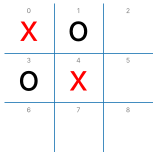


Number of nodes searched: 190


{'move': 2, 'value': 1}

CPU times: user 4.68 ms, sys: 93 μs, total: 4.77 ms
Wall time: 5.26 ms


In [4]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(minimax_search(board))

**Note:** DFS does not pick the the shortest path to a win! Discounting the utility can help.

### x can draw if it chooses 7

Board:


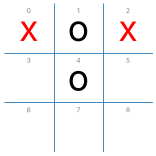


Number of nodes searched: 206


{'move': 7, 'value': 0}

CPU times: user 9.41 ms, sys: 0 ns, total: 9.41 ms
Wall time: 11.2 ms


In [5]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(minimax_search(board))

### A bad situation


Board:


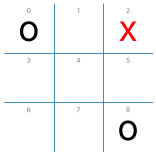


Number of nodes searched: 941


{'move': 1, 'value': -1}

CPU times: user 19.4 ms, sys: 0 ns, total: 19.4 ms
Wall time: 20.3 ms


In [6]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(minimax_search(board))

### Empty board

Board:


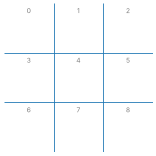

Number of nodes searched: 549946


{'move': 0, 'value': 0}

CPU times: user 10.7 s, sys: 8.19 ms, total: 10.7 s
Wall time: 10.9 s


In [7]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(minimax_search(board))

__Note:__ Starting with an empty board searched the complete game tree and takes a while. The number of nodes above is the actual size of the complete game tree. A table with know 'openings' (e.g., place x in a corner, o chooses the center, etc.) would be helpful to speed things up.

**Nhận xét – Minimax đầy đủ.**

* Minimax luôn duyệt **toàn bộ** cây con xuất phát từ trạng thái hiện tại: 190, 206 và 941 nút ở ba thế cờ giữa ván, và **549.946 nút** ở bàn cờ rỗng (mất vài giây) – đúng bằng số nút của cây trò chơi đã đếm ở notebook định nghĩa.
* Giá trị Minimax khớp với kết luận của AND-OR: `+1` (x sắp thắng), `0` (hòa nếu x chọn ô 7), `-1` (tình huống bất lợi: o thắng dù x chơi gì) và `0` ở bàn cờ rỗng (Tic-Tac-Toe là trò chơi hòa).
* Khác AND-OR (chỉ trả lời "có/không có kế hoạch"), Minimax gán **giá trị** cho mọi nước đi nên vẫn chọn được nước đi "ít tệ nhất" trong thế thua (ở đây là ô 1 với giá trị −1).

# Recursive DFS algorithm for Minimax Search with Alpha-Beta Pruning

See AIMA page 154. 

Adds alpha-beta pruning to minimax search. Alpha and beta are used to maintain bounds on the minimax value of a node in the form `[alpha, beta]`. alpha means that the value is at least that high and beta means that the actual value is at most that high. Subtrees below a node that are worse than the currently known bound do not need to be further explored and can be pruned. Max uses alpha and Min uses beta for pruning.

The implementation is for player 'x' returns a the optimal next move.

In [8]:
# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def alpha_beta_search(board, player = 'x'):
    """start the search."""
    global DEBUG, COUNT
    COUNT = 0
    
    value, move = max_value_ab(board, player, -math.inf, +math.inf)
    
    if DEBUG >= 1: print(f"Number of nodes searched: {COUNT}") 
    
    return { "move": move, "value": value }

def max_value_ab(state, player, alpha, beta):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
       
    # return utility of state is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print(f"max: {state} [alpha,beta]=[{alpha},{beta}] v={v}")
    if v is not None: 
        if DEBUG >= 2: print(f"     found terminal state. backtracking.")
        return v, None
        
    v, move = -math.inf, None

    # check all possible actions in the state, update alpha and return move with the largest value
    for a in actions(state):
        v2, a2 = min_value_ab(result(state, player, a), player, alpha, beta)
        if DEBUG >= 2: print(f"max: {state} (backtracked) [alpha,beta]=[{alpha},{beta}] v={v2}")
        
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta:
            if DEBUG >= 2: print(f"     v>=beta ({v}>={beta}): pruning remaining subtree (actions). backtracking.")
            return v, move
    
    return v, move

def min_value_ab(state, player, alpha, beta):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return utility of state is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print(f"min: {state} [alpha,beta]=[{alpha},{beta}] v={v}")
    if v is not None: 
        if DEBUG >= 2: print(f"     found terminal state. backtacking.")
        return v, None
    
    v, move = +math.inf, None

    # check all possible actions in the state, update beta and return move with the smallest value
    for a in actions(state):
        v2, a2 = max_value_ab(result(state, other(player), a), player, alpha, beta)
        if DEBUG >= 2: print(f"min: {state} (backtracked) [alpha,beta]=[{alpha},{beta}] v={v2}")
        
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: 
            if DEBUG >= 2: print(f"     v<=alpha ({v}<={alpha}): pruning remaining subtree (actions). backtracking.")
            return v, move
    
    return v, move

## Some Tests

### x is about to win (play 8)

Board:


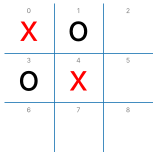


max: ['x', 'o', ' ', 'o', 'x', ' ', ' ', ' ', ' '] [alpha,beta]=[-inf,inf] v=None
min: ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', ' '] [alpha,beta]=[-inf,inf] v=None
max: ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '] [alpha,beta]=[-inf,inf] v=None
min: ['x', 'o', 'x', 'o', 'x', 'o', 'x', ' ', ' '] [alpha,beta]=[-inf,inf] v=1
     found terminal state. backtacking.
max: ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '] (backtracked) [alpha,beta]=[-inf,inf] v=1
min: ['x', 'o', 'x', 'o', 'x', 'o', ' ', 'x', ' '] [alpha,beta]=[1,inf] v=None
max: ['x', 'o', 'x', 'o', 'x', 'o', 'o', 'x', ' '] [alpha,beta]=[1,inf] v=None
min: ['x', 'o', 'x', 'o', 'x', 'o', 'o', 'x', 'x'] [alpha,beta]=[1,inf] v=1
     found terminal state. backtacking.
max: ['x', 'o', 'x', 'o', 'x', 'o', 'o', 'x', ' '] (backtracked) [alpha,beta]=[1,inf] v=1
min: ['x', 'o', 'x', 'o', 'x', 'o', ' ', 'x', ' '] (backtracked) [alpha,beta]=[1,inf] v=1
     v<=alpha (1<=1): pruning remaining subtree (actions). backtracking.
max: ['x', 'o'

{'move': 2, 'value': 1}

CPU times: user 3.82 ms, sys: 0 ns, total: 3.82 ms
Wall time: 3.7 ms


In [9]:
DEBUG = 2 # show more debugging info

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board))

The code does not pick the the shortest path to a win! Discounting could help.

### x can draw if it chooses 7

Board:


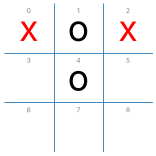


Number of nodes searched: 101


{'move': 7, 'value': 0}

CPU times: user 3.34 ms, sys: 0 ns, total: 3.34 ms
Wall time: 3.92 ms


In [10]:
DEBUG = 1

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board))

### o is about to win no matter what x does


Board:


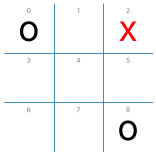


Number of nodes searched: 238


{'move': 1, 'value': -1}

CPU times: user 5.97 ms, sys: 17 μs, total: 5.99 ms
Wall time: 6.56 ms


In [11]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board))

### Empty board: Only a draw an be guaranteed

Board:


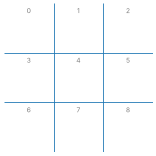

Number of nodes searched: 18297


{'move': 0, 'value': 0}

CPU times: user 349 ms, sys: 0 ns, total: 349 ms
Wall time: 350 ms


In [12]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(alpha_beta_search(board))

**Note:** Alpha-Beta search expands fewer nodes and is **much faster** than minimax search. 

## Move ordering

Smart move reordering can make alpha-beta pruning more effective. I think the center `[4]` and corners `[0, 2, 6, 8]` are good. I implement move reordering in the `actions()`.

**Nhận xét – Alpha-Beta.** Với cùng các thế cờ, Alpha-Beta trả về **cùng nước đi và cùng giá trị** với Minimax nhưng duyệt ít nút hơn nhiều: 206 → 101 nút (thế hòa), 941 → 238 nút (thế bất lợi) và **549.946 → 18.297 nút** ở bàn cờ rỗng (giảm khoảng 30 lần, thời gian giảm tương ứng). Hiệu quả tăng theo kích thước cây vì mỗi lần cắt tỉa loại bỏ cả một cây con. Bảng so sánh trên cùng tập trạng thái kiểm thử và phép kiểm tra "cắt tỉa không đổi quyết định" nằm ở phần bổ sung cuối notebook.

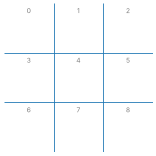

[4, 8, 6, 2, 0, 7, 5, 3, 1]

In [13]:
import numpy as np

def actions(board):
    """return possible actions as a vector ot indices"""
    actions = np.where(np.array(board) == ' ')[0].tolist()

    priority = [1,0,1,
                0,2,0,
                1,0,1]
    priority = [priority[i] for i in actions]
    
    actions =[a for _,a in sorted(zip(priority,actions), reverse=True)]
    
    return actions

board = empty_board()   
show_board(board)
actions(board)

### Empty board: Only a draw an be guaranteed

Board:


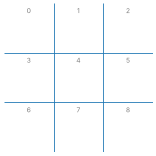

Number of nodes searched: 7275


{'move': 4, 'value': 0}

CPU times: user 149 ms, sys: 18 μs, total: 149 ms
Wall time: 150 ms


In [14]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(alpha_beta_search(board))

__Note:__ Compare to the number of nodes searched without move reordering (right above).

**Nhận xét – Move ordering.** Đưa các nước có triển vọng (ô giữa, rồi các góc) lên đầu `actions()` làm số nút ở bàn cờ rỗng giảm từ **18.297** xuống **7.275** (khoảng −60%), đồng thời nước đi đầu tiên đổi từ ô 0 sang **ô 4 (trung tâm)**; giá trị vẫn là 0 (hòa). Mọi nước đi đầu tiên đều có giá trị 0 nên việc nước nào được chọn chỉ phụ thuộc thứ tự duyệt (thuật toán giữ nước đầu tiên đạt giá trị lớn nhất). Phân tích chi tiết hơn (so sánh với thứ tự xấu nhất và ngẫu nhiên) ở phần bổ sung cuối notebook.

## Experiments


### Minimax with Alpha-Beta Pruning vs. Random

In [15]:
DEBUG = 0

def alpha_beta_player(board, player = 'x'):
    return alpha_beta_search(board, player)["move"]

print("alpha-beta vs. random:")
%time display(play(alpha_beta_player, random_player))

print()
print("random vs. alpha-beta")
%time display(play(random_player, alpha_beta_player))

alpha-beta vs. random:


{'x': 98, 'o': 0, 'd': 2}

CPU times: user 16.7 s, sys: 4.04 ms, total: 16.7 s
Wall time: 16.8 s

random vs. alpha-beta


{'x': 0, 'o': 78, 'd': 22}

CPU times: user 4.37 s, sys: 11 μs, total: 4.37 s
Wall time: 4.4 s


**Nhận xét – Alpha-Beta vs. Random (100 ván mỗi chiều).** `alpha_beta_player` chơi tối ưu nên **không thua ván nào** ở cả hai chiều (cột thắng của Random bằng 0). Khi đi trước (x) nó thắng gần hết các ván; khi đi sau (o) tỉ lệ hòa cao hơn vì đối thủ ngẫu nhiên đã đi trước và có thể vô tình chiếm các ô then chốt. So với AND-OR ở bài trước, Alpha-Beta dùng ít nút hơn nhiều nhưng vẫn mất vài giây cho 100 ván vì phải tìm kiếm lại từ đầu ở mỗi nước đi.

**Note on runtime:** Compared to AND-OR Search, Minimax search is slower, because AND-OR Search terminates once it finds the first subtree that has only goal nodes, buy Minimax search traverses the whole tree (minus what is pruned if alpha-beta pruning is used). 

Also, I was lazy and recreate the search tree every time the agent is asked for a move. The agent could create the tree with the Minimax values once and then use it to decide on actions. A problem could be that the tree may be too large to store. 

---
# Lab 05 – Bài 3: Thực hành bổ sung (Minimax vs. Alpha-Beta trên cùng tập kiểm thử, kiểm chứng và Move ordering)

> Các ô phía trên là nội dung gốc của giảng viên (giữ nguyên). Phần dưới thực hiện đúng yêu cầu của Bài 3:
> 1. chạy **cùng một tập trạng thái kiểm thử** cho `minimax_search` và `alpha_beta_search`, ghi nước đi, giá trị Minimax, số nút và thời gian;
> 2. kiểm tra cắt tỉa Alpha-Beta **không đổi quyết định tối ưu**;
> 3. thử **move ordering**, so sánh số nút trước/sau và giải thích.

In [16]:
import time
import numpy as np
import pandas as pd
import tictactoe

# Hai cách sắp xếp hành động. Các hàm tìm kiếm ở trên gọi tên `actions` (biến toàn cục của notebook)
# nên ta chỉ cần gán lại biến này để đổi thứ tự duyệt.
actions_natural  = tictactoe.actions     # chỉ số tăng dần, không sắp xếp lại
actions_ordered  = actions               # thứ tự ưu tiên (giữa > góc > cạnh) đã định nghĩa ở phần Move ordering

def use_actions(fn):
    globals()['actions'] = fn

def make_board(**cells):
    b = empty_board()
    for symbol, idx in cells.items():
        for i in idx: b[i] = symbol
    return b

# Tập trạng thái kiểm thử (x luôn là người đến lượt và là Max). Giống tập kiểm thử của Bài 4.
TESTS = {
    "X sắp thắng"         : make_board(x=[0, 4], o=[1, 3]),
    "X cần tìm đường hòa" : make_board(x=[0, 2], o=[1, 4]),
    "Tình huống bất lợi"  : make_board(x=[2], o=[0, 8]),
    "O sắp thắng"         : make_board(x=[4, 8], o=[0, 1, 3]),
    "Bàn cờ rỗng"         : empty_board(),
}

def run_search(fn, b, player = 'x'):
    """chạy một thuật toán, trả về (nước đi, giá trị, số nút, thời gian ms)"""
    global DEBUG
    DEBUG = 0
    t0 = time.perf_counter()
    r = fn(b, player)
    ms = (time.perf_counter() - t0) * 1000
    return r["move"], r["value"], COUNT, ms

use_actions(actions_natural)       # so sánh công bằng: cả hai thuật toán dùng cùng thứ tự duyệt
rows = []
for name, b in TESTS.items():
    m1, v1, n1, t1 = run_search(minimax_search,    b)
    m2, v2, n2, t2 = run_search(alpha_beta_search, b)
    rows.append({"Trạng thái": name,
                 "Minimax: nước": m1, "giá trị": v1, "số nút": n1, "ms": round(t1, 1),
                 "Alpha-Beta: nước": m2, "giá trị ": v2, "số nút ": n2, "ms ": round(t2, 1),
                 "Cùng quyết định?": (m1 == m2 and v1 == v2),
                 "Tỉ lệ nút": f"{n1 / n2:.1f}x"})
cmp_table = pd.DataFrame(rows)
display(cmp_table)
assert cmp_table["Cùng quyết định?"].all()
print("=> Alpha-Beta cho cùng nước đi và cùng giá trị Minimax trên cả 5 trạng thái kiểm thử.")

,Trạng thái,Minimax: nước,giá trị,số nút,ms,Alpha-Beta: nước,giá trị,số nút,ms,Cùng quyết định?,Tỉ lệ nút
0,X sắp thắng,2,1,190,4.0,2,1,61,1.2,True,3.1x
1,X cần tìm đường hòa,7,0,206,4.0,7,0,101,2.0,True,2.0x
2,Tình huống bất lợi,1,-1,941,17.6,1,-1,238,4.7,True,4.0x
3,O sắp thắng,2,-1,33,0.7,2,-1,15,0.3,True,2.2x
4,Bàn cờ rỗng,0,0,549946,10117.1,0,0,18297,355.1,True,30.1x


=> Alpha-Beta cho cùng nước đi và cùng giá trị Minimax trên cả 5 trạng thái kiểm thử.


In [17]:
# Kiểm tra mở rộng: Alpha-Beta có đổi quyết định tối ưu ở MỌI thế cờ đạt được (còn <= 6 ô trống) không?
from tictactoe import check_board, other

start = tuple(empty_board())
reach, frontier = {start: 'x'}, [(start, 'x')]
while frontier:
    nxt = []
    for s, p in frontier:
        if check_board(list(s)) != 'n':
            continue
        for a in actions_natural(list(s)):
            c = tuple(result(list(s), p, a))
            if c not in reach:
                reach[c] = other(p); nxt.append((c, other(p)))
    frontier = nxt

to_check = [(list(s), p) for s, p in reach.items()
            if check_board(list(s)) == 'n' and list(s).count(' ') <= 6]
print(f"Số thế cờ chưa kết thúc có <= 6 ô trống: {len(to_check):,}")

t0 = time.perf_counter()
diff_move = diff_value = 0
nodes_mm = nodes_ab = 0
for s, p in to_check:
    m1, v1, n1, _ = run_search(minimax_search,    s, p)
    m2, v2, n2, _ = run_search(alpha_beta_search, s, p)
    nodes_mm += n1; nodes_ab += n2
    diff_move  += (m1 != m2)
    diff_value += (v1 != v2)
print(f"Thế cờ khác nước đi : {diff_move}")
print(f"Thế cờ khác giá trị : {diff_value}")
print(f"Tổng số nút: Minimax {nodes_mm:,}  |  Alpha-Beta {nodes_ab:,}  (giảm {1 - nodes_ab/nodes_mm:.1%})")
print(f"Thời gian kiểm tra: {time.perf_counter() - t0:.1f} s")

Số thế cờ chưa kết thúc có <= 6 ô trống: 4,438


Thế cờ khác nước đi : 0
Thế cờ khác giá trị : 0
Tổng số nút: Minimax 475,708  |  Alpha-Beta 163,923  (giảm 65.5%)
Thời gian kiểm tra: 11.6 s


**Kết luận kiểm chứng.** Trên **toàn bộ** các thế cờ chưa kết thúc còn không quá 6 ô trống, Alpha-Beta cho kết quả *giống hệt* Minimax về cả nước đi lẫn giá trị (0 trường hợp khác nhau), đồng thời duyệt ít nút hơn rõ rệt.
Điều này đúng vì Alpha-Beta chỉ cắt những nhánh **không thể ảnh hưởng** đến giá trị ở gốc: khi `v ≥ β` ở nút Max (hoặc `v ≤ α` ở nút Min), nút cha (Min/Max) đã có một lựa chọn tốt hơn nên nhánh còn lại không bao giờ được chọn.
Thuật toán dùng so sánh *chặt* (`v2 > v`) để chọn nước nên nước được trả về là nước đầu tiên đạt giá trị lớn nhất – giống hệt Minimax.

## Move ordering: so sánh số nút duyệt trước và sau khi đổi thứ tự nước đi

Ta so sánh 4 cách sắp xếp hành động cho **cùng một** thuật toán Alpha-Beta:

| Chiến lược | Thứ tự duyệt |
|---|---|
| Tự nhiên | chỉ số tăng dần `0,1,2,…,8` (không sắp xếp) |
| Tốt trước (ordering của notebook) | ô giữa → các góc → các cạnh |
| Xấu trước | các cạnh → các góc → ô giữa (ngược với "tốt trước") |
| Ngẫu nhiên | xáo trộn ngẫu nhiên (trung bình 30 lần chạy) |

,Trạng thái,Giá trị Minimax,Tự nhiên,Tốt trước,Xấu trước,Ngẫu nhiên (TB)
0,X sắp thắng,1,61,42,148,58.2
1,X cần tìm đường hòa,0,101,106,84,88.3
2,Tình huống bất lợi,-1,238,36,565,194.1
3,O sắp thắng,-1,15,13,31,20.2
4,Bàn cờ rỗng,0,18297,7275,42094,15466.8


,Trạng thái,Tự nhiên (ms),Tốt trước (ms),Xấu trước (ms),Ngẫu nhiên (ms)
0,X sắp thắng,2.1,1.0,3.3,1.7
1,X cần tìm đường hòa,2.1,2.3,1.7,2.1
2,Tình huống bất lợi,4.9,0.7,11.9,4.5
3,O sắp thắng,0.4,0.4,0.8,0.5
4,Bàn cờ rỗng,389.2,163.3,914.9,339.7


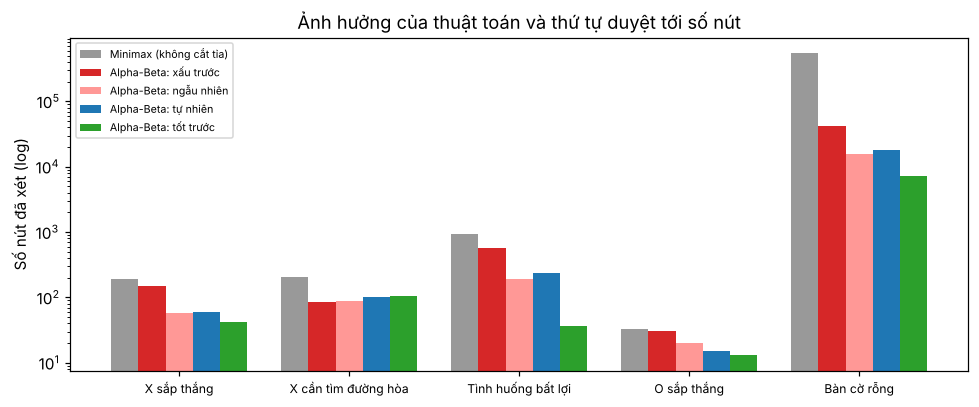


**Bàn cờ rỗng:** Minimax 549,946 nút → Alpha-Beta (tự nhiên) 18,297 nút → Alpha-Beta (tốt trước) 7,275 nút
(giảm 60% so với thứ tự tự nhiên); thứ tự **xấu trước** cần 42,094 nút và thứ tự ngẫu nhiên trung bình 15,467 nút.


In [18]:
import matplotlib.pyplot as plt

def make_ordered(priority):
    """priority[i] càng lớn thì ô i càng được duyệt sớm"""
    def f(board):
        acts = tictactoe.actions(board)
        return sorted(acts, key = lambda a: -priority[a])
    return f

actions_worst = make_ordered([0,1,0, 1,-1,1, 0,1,0])       # cạnh > góc > giữa

def actions_random(board):
    acts = tictactoe.actions(board)
    np.random.shuffle(acts)
    return acts

ORDERINGS = {"Tự nhiên": actions_natural, "Tốt trước": actions_ordered, "Xấu trước": actions_worst}

np.random.seed(2026)
rows = []
for name, b in TESTS.items():
    row = {"Trạng thái": name}
    values = set()
    for oname, fn in ORDERINGS.items():
        use_actions(fn)
        m, v, n, ms = run_search(alpha_beta_search, b)
        row[oname] = n; values.add(v)
        row[oname + " (ms)"] = round(ms, 1)
    # ngẫu nhiên: trung bình 30 lần
    use_actions(actions_random)
    ns, mss = [], []
    for _ in range(30):
        m, v, n, ms = run_search(alpha_beta_search, b)
        ns.append(n); mss.append(ms); values.add(v)
    row["Ngẫu nhiên (TB)"] = round(np.mean(ns), 1)
    row["Ngẫu nhiên (ms)"] = round(np.mean(mss), 1)
    assert len(values) == 1, "giá trị Minimax không được phụ thuộc vào thứ tự duyệt"
    row["Giá trị Minimax"] = v
    rows.append(row)
use_actions(actions_ordered)       # trả về trạng thái ban đầu của notebook

mo = pd.DataFrame(rows)
display(mo[["Trạng thái", "Giá trị Minimax", "Tự nhiên", "Tốt trước", "Xấu trước", "Ngẫu nhiên (TB)"]])
display(mo[["Trạng thái", "Tự nhiên (ms)", "Tốt trước (ms)", "Xấu trước (ms)", "Ngẫu nhiên (ms)"]])

# so với Minimax không cắt tỉa
mm_nodes = {name: run_search(minimax_search, b)[2] for name, b in TESTS.items()}

fig, ax = plt.subplots(figsize = (9, 3.8), dpi = 110)
x = np.arange(len(TESTS)); w = 0.16
series = [("Minimax (không cắt tỉa)", [mm_nodes[n] for n in TESTS], "#999999"),
          ("Alpha-Beta: xấu trước",   list(mo["Xấu trước"]), "#d62728"),
          ("Alpha-Beta: ngẫu nhiên",  list(mo["Ngẫu nhiên (TB)"]), "#ff9896"),
          ("Alpha-Beta: tự nhiên",    list(mo["Tự nhiên"]), "#1f77b4"),
          ("Alpha-Beta: tốt trước",   list(mo["Tốt trước"]), "#2ca02c")]
for k, (lab, vals, col) in enumerate(series):
    ax.bar(x + (k - 2) * w, vals, w, label = lab, color = col)
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(list(TESTS), fontsize = 8)
ax.set_ylabel("Số nút đã xét (log)"); ax.set_title("Ảnh hưởng của thuật toán và thứ tự duyệt tới số nút")
ax.legend(fontsize = 7); plt.tight_layout(); plt.show()

empty = mo[mo["Trạng thái"] == "Bàn cờ rỗng"].iloc[0]
from IPython.display import Markdown
display(Markdown(f"""
**Bàn cờ rỗng:** Minimax {mm_nodes['Bàn cờ rỗng']:,} nút → Alpha-Beta (tự nhiên) {empty['Tự nhiên']:,} nút → Alpha-Beta (tốt trước) {empty['Tốt trước']:,} nút
(giảm {1 - empty['Tốt trước']/empty['Tự nhiên']:.0%} so với thứ tự tự nhiên); thứ tự **xấu trước** cần {empty['Xấu trước']:,} nút và thứ tự ngẫu nhiên trung bình {empty['Ngẫu nhiên (TB)']:,.0f} nút.
"""))

**Giải thích – vì sao thứ tự nước đi tốt làm tăng hiệu quả cắt tỉa.**

* Alpha-Beta chỉ cắt khi đã có một cận (`α` ở nút Max, `β` ở nút Min) đủ chặt. Cận này đến từ các nước đã được duyệt **trước**. Nếu nước tốt nhất được duyệt đầu tiên, cận `α`/`β` trở nên chặt ngay từ đầu, nên hầu hết các nước còn lại bị cắt sau khi chỉ xét một vài nút con.
* Ngược lại, nếu nước tệ được duyệt trước thì cận còn lỏng, thuật toán phải khai triển nhiều nhánh vô ích trước khi tìm được nước tốt, và khi đó cắt tỉa gần như không xảy ra (trường hợp xấu nhất: số nút tiến gần Minimax, $O(b^m)$).
* Với thứ tự lý tưởng, số nút giảm xuống khoảng $O(b^{m/2})$, nghĩa là cùng ngân sách thời gian có thể tìm sâu gần gấp đôi. Đó là lý do trong các trò chơi lớn (cờ vua, Connect 4) người ta dùng **sắp xếp nước đi** (nước ăn quân, nước giữa bàn, nước tốt ở lần duyệt trước/iterative deepening…).
* Ở Tic-Tac-Toe, ô giữa và các góc nằm trên nhiều đường thắng nhất (ô giữa 4 đường, mỗi góc 3 đường, mỗi cạnh 2 đường) nên thường là nước triển vọng. Ở bàn cờ rỗng thứ tự "tốt trước" cần **7.275** nút, "tự nhiên" **18.297** nút và "xấu trước" **42.094** nút; ở thế "tình huống bất lợi" là 36 / 238 / 565 nút. Giá trị Minimax **không đổi** (đã kiểm tra bằng `assert`).
* Tuy nhiên sắp xếp tĩnh chỉ là *heuristic*: ở thế "X cần tìm đường hòa", nước duy nhất không thua (ô 7) lại là một ô cạnh nên thứ tự "xấu trước" (84 nút) lại tốt hơn "tốt trước" (106 nút). Thứ tự lý tưởng là đặt **nước tốt nhất thật sự** lên đầu, điều mà các chương trình thực tế xấp xỉ bằng iterative deepening hoặc bảng nước đi tốt nhất của lần duyệt trước.
* Lưu ý: thứ tự duyệt chỉ ảnh hưởng *hiệu quả*, không ảnh hưởng *giá trị*; nước đi được chọn có thể đổi (ví dụ ô 0 → ô 4 ở bàn cờ rỗng) khi có nhiều nước cùng giá trị.